# 01 — Data Exploration & Feature Extraction

**Goal of this notebook:** turn 280 raw WAV files into 280 fixed-length numeric vectors (embeddings) that a classifier can learn from, and along the way, convince ourselves the data is clean and understood.

This notebook does **not** train anything. It only:
1. Loads and sanity-checks `labels.csv` against the audio files.
2. Explores how the data is *sorted* — by participant, session, and activity type — because that structure is exactly what makes fair evaluation possible later.
3. Extracts a frozen, pretrained speech embedding (`wav2vec2-base`) for every recording and caches it to disk.

The actual training happens in `02_train_evaluate.ipynb`, which loads the embeddings cached here. See the **"How the data is sorted"** and **"How training will work"** sections below for the conceptual walkthrough — read those before running code if you want the full picture first.

---

## How the data is sorted (and why it matters)

Every row in `labels.csv` belongs to exactly one **participant** (`participant_id`, 14 people), and within a participant, to one **session** (`session_number`) — a single visit where that person recorded **three activities** back-to-back: `read_aloud`, `read_aloud_nonsense`, `describe_picture`. All three recordings in a session share **one fatigue label**, because the label describes the person's state at that visit, not the individual clip.

```
participant_id (14 people)
  └── session_number (a visit; ~1 fatigue label per visit)
        └── activity_type × 3 (read_aloud / read_aloud_nonsense / describe_picture)
              → one WAV file each = 280 files total
```

The reason this hierarchy matters: **a person's voice is a strong identity signal**, independent of fatigue. If clips from the same participant end up in both the training set and the test set, a classifier can partly (or mostly) learn to recognize *who is speaking* rather than *how fatigued they sound* — and that leaks into inflated accuracy that won't generalize to a new person. This is documented in the literature as a common failure mode in this exact kind of study (see `PROJECT_PLAN.md`).

So every split used anywhere in this project — later, in training — is **grouped by `participant_id`**: a person is entirely in the train set or entirely in the test set, never split across both. This notebook's exploration section below groups by participant for the same reason: to see the data the way it will actually be evaluated.

## How training will work (preview — implemented in `02_train_evaluate.ipynb`)

Once this notebook produces one embedding vector per recording, `02_train_evaluate.ipynb` will:

1. **Outer loop — Leave-One-Speaker-Out (LOSO):** hold out *all* of one participant's recordings as the test set, train on the other 13 participants, repeat for all 14 participants. This gives 14 honest "what happens with a brand-new person" tests.
2. **Inner loop — `GroupKFold(6)`:** *within* each outer training set (13 participants), split into 6 groups (again by participant) purely to pick hyperparameters (e.g. how much regularization). The held-out outer-test participant never touches this step.
3. **Retrain once** on the full 13-participant outer-training set with the chosen hyperparameters, then evaluate **once** on the held-out participant.
4. Pool all 14 outer test predictions together and compute metrics (ROC-AUC primarily), plus bootstrap confidence intervals and a permutation test to check the result isn't a fluke.

The model itself is deliberately simple: a **frozen** (not fine-tuned) pretrained speech model produces the embeddings (this notebook), and a **simple regularized linear classifier** (logistic regression / linear SVM) sits on top (next notebook). With only 14 speakers, a big fine-tuned deep network would almost certainly just memorize them instead of learning generalizable fatigue cues — this is why extraction (expensive, one-time, GPU) and training (cheap, iterative, CPU) are split into two notebooks.

## 0. Setup

In [1]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("*"):
    if p.is_dir():
        print(p)


/kaggle/input/datasets
/kaggle/input/datasets/tapudatta
/kaggle/input/datasets/tapudatta/fatigue-data
/kaggle/input/datasets/tapudatta/fatigue-data/project_data
/kaggle/input/datasets/tapudatta/fatigue-data/project_data/audio


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt

# Kaggle mounts uploaded datasets read-only somewhere under /kaggle/input/ —
# the exact depth varies (classic: /kaggle/input/<slug>/..., newer UI:
# /kaggle/input/datasets/<owner>/<slug>/...), so rather than assume a fixed
# depth, search recursively for the one folder we know must exist: project_data/.
DATA_DIR = next(Path("/kaggle/input").rglob("project_data"))
AUDIO_DIR = DATA_DIR / "audio"
LABELS_CSV = DATA_DIR / "labels.csv"

OUT_DIR = Path("/kaggle/working/features")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"DATA_DIR   = {DATA_DIR}")
print(f"AUDIO_DIR  = {AUDIO_DIR}")
print(f"LABELS_CSV = {LABELS_CSV}")

DATA_DIR   = /kaggle/input/datasets/tapudatta/fatigue-data/project_data
AUDIO_DIR  = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/audio
LABELS_CSV = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv


## 1. Load & Validate Labels

First check the metadata is internally consistent before trusting anything derived from it: every row in `labels.csv` should point to a real file, and the counts should match what `PROJECT_PLAN.md` documents (280 recordings, 14 participants, 147 `non_fatigued` / 133 `fatigued`).

In [3]:
labels = pd.read_csv(LABELS_CSV)
print(f"labels.csv: {len(labels)} rows")
labels.head()

labels.csv: 280 rows


,filename,participant_id,session_number,activity_type,label
0,P-33B7FA2A_s01_describe_picture.wav,P-33B7FA2A,1,describe_picture,non_fatigued
1,P-33B7FA2A_s01_read_aloud.wav,P-33B7FA2A,1,read_aloud,non_fatigued
2,P-33B7FA2A_s01_read_aloud_nonsense.wav,P-33B7FA2A,1,read_aloud_nonsense,non_fatigued
3,P-33B7FA2A_s02_describe_picture.wav,P-33B7FA2A,2,describe_picture,fatigued
4,P-33B7FA2A_s02_read_aloud.wav,P-33B7FA2A,2,read_aloud,fatigued


In [4]:
# Every filename in labels.csv must resolve to a real file in audio/
missing = [f for f in labels["filename"] if not (AUDIO_DIR / f).exists()]
assert not missing, f"{len(missing)} filenames in labels.csv have no matching audio file: {missing[:5]}"

# Every file in audio/ should also be referenced in labels.csv (catches stray/extra files)
audio_files = {p.name for p in AUDIO_DIR.glob("*.wav")}
unreferenced = audio_files - set(labels["filename"])
assert not unreferenced, f"{len(unreferenced)} audio files are not referenced in labels.csv: {list(unreferenced)[:5]}"

print("All labels.csv rows resolve to real audio files, and vice versa.")
print(f"Recordings:    {len(labels)} (expected 280)")
print(f"Participants:  {labels['participant_id'].nunique()} (expected 14)")
print(f"Label counts:\n{labels['label'].value_counts()}")

All labels.csv rows resolve to real audio files, and vice versa.
Recordings:    280 (expected 280)
Participants:  14 (expected 14)
Label counts:
label
non_fatigued    147
fatigued        133
Name: count, dtype: int64


## 2. Per-Participant Breakdown

This is the view that matters for evaluation: how many recordings and sessions each participant contributes, and their label split. Contribution is expected to be **wildly uneven** (6 to 42 recordings per participant) — this isn't a bug to fix, but it means later, in LOSO, the fold for a 6-recording participant will be noisier/higher-variance than the fold for a 42-recording participant. We flag that here so it's not a surprise later.

In [5]:
per_participant = (
    labels.groupby("participant_id")
    .agg(
        n_recordings=("filename", "count"),
        n_sessions=("session_number", "nunique"),
        n_fatigued=("label", lambda s: (s == "fatigued").sum()),
        n_non_fatigued=("label", lambda s: (s == "non_fatigued").sum()),
    )
    .sort_values("n_recordings")
)
print(per_participant)

small_n = per_participant[per_participant["n_recordings"] <= 6]
print(f"\nParticipants with <=6 recordings (expect noisy individual LOSO folds): {list(small_n.index)}")

                n_recordings  n_sessions  n_fatigued  n_non_fatigued
participant_id                                                      
P-33B7FA2A                 6           2           3               3
P-5AE2B073                 6           2           3               3
P-FB31ADB8                 6           2           3               3
P-FC309883                 6           2           3               3
P-8A4B73A3                11           4           2               9
P-B116746A                12           4           6               6
P-4F8CDB03                20           7          11               9
P-4B5527A7                21           7           9              12
P-66395191                21           7          12               9
P-87C2E2A3                21           7           9              12
P-E2F94BC4                30          10          15              15
P-E0BE51FC                36          12          18              18
P-7DB1F098                42      

## 3. Audio Format Check

Confirm every file matches the stated format (16kHz, mono) and look at the distribution of clip durations. `soundfile.info()` reads just the file header, not the full waveform, so this is fast even for 280 files.

In [6]:
records = []
for f in labels["filename"]:
    info = sf.info(AUDIO_DIR / f)
    records.append(
        {
            "filename": f,
            "samplerate": info.samplerate,
            "channels": info.channels,
            "duration_sec": info.frames / info.samplerate,
        }
    )
audio_info = pd.DataFrame(records)

bad_format = audio_info[(audio_info["samplerate"] != 16000) | (audio_info["channels"] != 1)]
if len(bad_format):
    print(f"WARNING: {len(bad_format)} files are not 16kHz mono:")
    print(bad_format)
else:
    print("All 280 files confirmed 16kHz mono.")

print(f"\nDuration (sec): min={audio_info['duration_sec'].min():.1f}, "
      f"median={audio_info['duration_sec'].median():.1f}, "
      f"max={audio_info['duration_sec'].max():.1f}")

All 280 files confirmed 16kHz mono.

Duration (sec): min=10.3, median=50.0, max=100.3


## 4. Sanity Plots

Two quick checks: is the overall label balance close to the documented 147/133, and is that balance roughly stable across the three activity types (if one activity type were skewed heavily toward one label, that would be a confound worth knowing about before modeling).

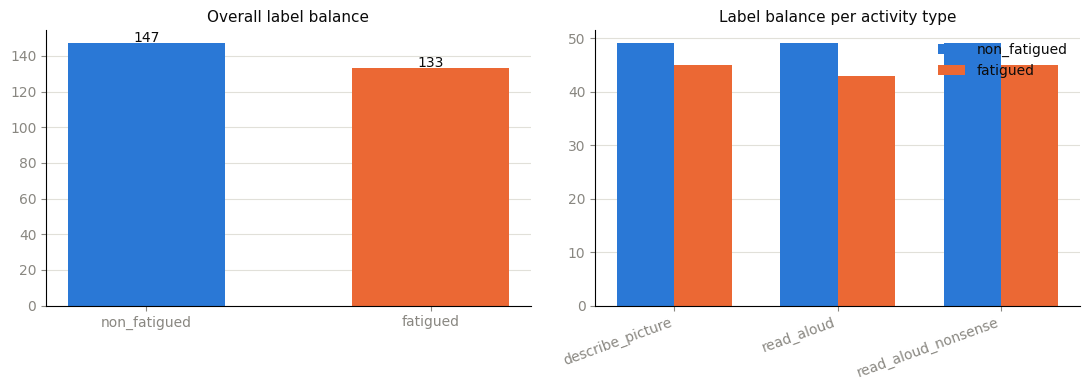

In [7]:
# Colors: fixed categorical order, not cycled — blue = non_fatigued, orange = fatigued
COLOR_NON_FATIGUED = "#2a78d6"
COLOR_FATIGUED = "#eb6834"
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Overall label balance
counts = labels["label"].value_counts()[["non_fatigued", "fatigued"]]
axes[0].bar(counts.index, counts.values, color=[COLOR_NON_FATIGUED, COLOR_FATIGUED], width=0.55)
axes[0].set_title("Overall label balance", color=INK, fontsize=11)
axes[0].tick_params(colors=MUTED)
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
axes[0].set_axisbelow(True)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1, str(v), ha="center", color=INK, fontsize=10)

# Label balance per activity type
by_activity = labels.groupby(["activity_type", "label"]).size().unstack()[["non_fatigued", "fatigued"]]
x = np.arange(len(by_activity))
width = 0.35
axes[1].bar(x - width / 2, by_activity["non_fatigued"], width, label="non_fatigued", color=COLOR_NON_FATIGUED)
axes[1].bar(x + width / 2, by_activity["fatigued"], width, label="fatigued", color=COLOR_FATIGUED)
axes[1].set_xticks(x)
axes[1].set_xticklabels(by_activity.index, rotation=20, ha="right", color=MUTED)
axes[1].set_title("Label balance per activity type", color=INK, fontsize=11)
axes[1].tick_params(colors=MUTED)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
axes[1].set_axisbelow(True)
axes[1].legend(frameon=False, labelcolor=INK)

plt.tight_layout()
plt.show()

## 5. Feature Extraction — Frozen SSL Embeddings

This is the slow, GPU-bound part of the pipeline, and the reason this notebook exists separately from training.

**What we're doing and why:**

- **Why a pretrained model instead of hand-crafted features (pitch, MFCCs, energy):** self-supervised speech models like `wav2vec2` are trained on thousands of hours of raw audio to predict masked chunks of speech, which forces them to learn rich, general representations of *how a voice sounds* — prosody, voice quality, timing — without ever being told a task. Prior work on this exact problem shows these embeddings substantially outperform classical acoustic features for fatigue/sleepiness-from-speech tasks.
- **Why *frozen* (not fine-tuned):** fine-tuning means further training the pretrained model's own weights on our data. With only 14 participants, a fine-tuned model has enough capacity to just memorize who's who instead of learning fatigue cues that transfer to a new person. Freezing it means we only ever *read out* its existing representation — the model's weights never change, so it can't overfit to our tiny set of speakers. Only the small classifier trained in notebook 02 (on top of these frozen features) gets fit to our data.
- **Silence trimming:** each recording likely has leading/trailing silence from the recording setup; trimming it means the embedding is computed only from actual speech, not dead air.
- **Mean + std pooling:** the model outputs one 768-dim vector *per time step* (i.e., a variable-length sequence, since clips vary in duration). To get one *fixed-size* vector per recording — which any standard classifier needs — we pool across time: the **mean** captures the average voice characteristics, and the **standard deviation** captures how much they vary over the clip (e.g. a fatigued voice might be flatter/more monotone, which shows up as *lower* variance over time). Concatenating both gives a 1536-dim vector per recording, keeping both signals instead of only the average.

The result of this section: one row per recording, each with a 1536-dim embedding, cached to `/kaggle/working/features/wav2vec2_base.parquet`. Notebook 02 loads this file directly and never needs to touch raw audio.

In [8]:
!pip install -q transformers

In [9]:
import librosa
import torch
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model

MODEL_NAME = "facebook/wav2vec2-base"
SAMPLE_RATE = 16000

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_NAME)
model = Wav2Vec2Model.from_pretrained(MODEL_NAME).to(device)
model.eval()  # frozen: no gradient updates, ever

Using device: cuda


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/380M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Wav2Vec2Model(
  (feature_extractor): Wav2Vec2FeatureEncoder(
    (conv_layers): ModuleList(
      (0): Wav2Vec2GroupNormConvLayer(
        (conv): Conv1d(1, 512, kernel_size=(10,), stride=(5,), bias=False)
        (activation): GELUActivation()
        (layer_norm): GroupNorm(512, 512, eps=1e-05, affine=True)
      )
      (1-4): 4 x Wav2Vec2NoLayerNormConvLayer(
        (conv): Conv1d(512, 512, kernel_size=(3,), stride=(2,), bias=False)
        (activation): GELUActivation()
      )
      (5-6): 2 x Wav2Vec2NoLayerNormConvLayer(
        (conv): Conv1d(512, 512, kernel_size=(2,), stride=(2,), bias=False)
        (activation): GELUActivation()
      )
    )
  )
  (feature_projection): Wav2Vec2FeatureProjection(
    (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
    (projection): Linear(in_features=512, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): Wav2Vec2Encoder(
    (pos_conv_embed): Wav2Vec2PositionalConvEmbedding(
  

In [10]:
def extract_embedding(wav_path: Path) -> np.ndarray:
    """Load one recording -> trim silence -> frozen wav2vec2 forward pass ->
    mean+std pool over time -> a single 1536-dim vector."""
    y, _ = librosa.load(wav_path, sr=SAMPLE_RATE, mono=True)
    y_trimmed, _ = librosa.effects.trim(y, top_db=25)

    inputs = feature_extractor(y_trimmed, sampling_rate=SAMPLE_RATE, return_tensors="pt")
    input_values = inputs.input_values.to(device)

    with torch.no_grad():
        hidden_states = model(input_values).last_hidden_state.squeeze(0)  # (T, 768)

    mean_pool = hidden_states.mean(dim=0)
    std_pool = hidden_states.std(dim=0)
    embedding = torch.cat([mean_pool, std_pool]).cpu().numpy()  # (1536,)
    return embedding

In [11]:
from tqdm.auto import tqdm

rows = []
for filename in tqdm(labels["filename"], desc="Extracting embeddings"):
    emb = extract_embedding(AUDIO_DIR / filename)
    rows.append({"filename": filename, **{f"emb_{i}": v for i, v in enumerate(emb)}})

embeddings_df = pd.DataFrame(rows)
print(embeddings_df.shape)
embeddings_df.head()

Extracting embeddings:   0%|          | 0/280 [00:00<?, ?it/s]

(280, 1537)


,filename,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,emb_7,emb_8,...,emb_1526,emb_1527,emb_1528,emb_1529,emb_1530,emb_1531,emb_1532,emb_1533,emb_1534,emb_1535
0,P-33B7FA2A_s01_describe_picture.wav,-0.233056,-0.045710,0.048603,0.225034,0.206359,-0.160350,0.176752,-0.196951,-0.053506,...,0.292342,0.101749,0.178830,0.410078,0.283067,0.072791,0.070739,0.263441,0.202248,0.155923
1,P-33B7FA2A_s01_read_aloud.wav,-0.228370,-0.078228,0.182063,0.251625,0.219035,-0.139451,0.190484,-0.194009,-0.108142,...,0.273965,0.076175,0.176345,0.437785,0.277176,0.079631,0.075556,0.257575,0.200142,0.131921
2,P-33B7FA2A_s01_read_aloud_nonsense.wav,-0.188252,-0.049879,0.036075,0.259793,0.223564,-0.120754,0.219836,-0.192931,-0.010497,...,0.272978,0.092459,0.202435,0.444212,0.282140,0.085995,0.081150,0.278292,0.199288,0.133925
3,P-33B7FA2A_s02_describe_picture.wav,-0.159982,-0.105139,0.166216,0.163181,0.315701,-0.254138,0.150468,-0.163936,-0.033022,...,0.329166,0.114213,0.167387,0.402006,0.268478,0.073964,0.074910,0.242819,0.186279,0.156455
4,P-33B7FA2A_s02_read_aloud.wav,-0.248200,-0.062633,0.208589,0.204244,0.225978,-0.185675,0.148806,-0.152540,-0.088661,...,0.286185,0.080581,0.166412,0.417206,0.278490,0.080441,0.077126,0.236817,0.205026,0.134987


## 6. Cache Embeddings & Verify

Save to `/kaggle/working/features/`, then run the exact checks from the project's verification checklist. Notebook 02 will merge this file with `labels.csv` on `filename` to bring back `participant_id`, `session_number`, `activity_type`, and `label` for grouped CV — kept separate here since embeddings and labels are logically different things, and it keeps this cache reusable if labels ever change.

In [12]:
out_path = OUT_DIR / "wav2vec2_base.parquet"
embeddings_df.to_parquet(out_path, index=False)

# Verification checklist (from PROJECT_PLAN.md):
assert len(embeddings_df) == 280, f"expected 280 rows, got {len(embeddings_df)}"
n_emb_cols = sum(c.startswith("emb_") for c in embeddings_df.columns)
assert n_emb_cols == 1536, f"expected 1536 embedding dims, got {n_emb_cols}"
assert set(embeddings_df["filename"]) == set(labels["filename"]), "filename mismatch vs labels.csv"

print(f"Saved {out_path}")
print(f"Shape: {embeddings_df.shape} (280 rows x 1 filename + 1536 embedding dims)")
print("All verification checks passed.")

Saved /kaggle/working/features/wav2vec2_base.parquet
Shape: (280, 1537) (280 rows x 1 filename + 1536 embedding dims)
All verification checks passed.


## Next steps

1. **Save this notebook's version** (Kaggle: "Save Version" — required, since `/kaggle/working/` is otherwise wiped when the session ends).
2. In `02_train_evaluate.ipynb`, attach this notebook's output as an input dataset, so it can load `wav2vec2_base.parquet` directly instead of re-extracting.
3. Notebook 02 implements the nested LOSO → GroupKFold(6) protocol described above, and reports pooled ROC-AUC, balanced accuracy, F1, bootstrap CI, and a permutation test — all grouped by `participant_id` throughout, so no person's voice ever appears in both a training and a test fold at either the outer or inner level.